# Lab 2: Path finding (BFS, DFS and A*)
Environment (Anaconda): `conda activate ailab`, then `jupyter notebook`. Run cells top to bottom with **Shift+Enter**.

**Problem:** a robot moves on a grid map (4 directions, cost 1 per move) from START to GOAL. We compare how many cells each algorithm opens and how long the path is.

## Cell 1: Setup and random map

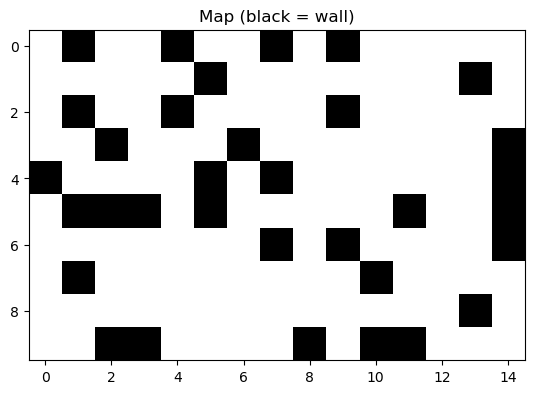

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import heapq
from collections import deque

ROWS, COLS = 10, 15          # map size
WALL_PROB = 0.25             # chance that a cell is a wall
SEED = 3                # makes the random map repeatable
START = (0, 0)               # (row, column)
GOAL = (ROWS - 1, COLS - 1)
MOVES = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right

rng = np.random.default_rng(SEED)
grid = (rng.random((ROWS, COLS)) < WALL_PROB).astype(int)   # 1 = wall
grid[START] = 0
grid[GOAL] = 0

plt.imshow(grid, cmap="Greys")
plt.title("Map (black = wall)")
plt.show()

## Cell 2: BFS and DFS in one function (only `popleft` vs `pop` differs)

In [23]:
def blind_search(grid, start, goal, mode):
    frontier = deque([start])
    came_from = {start: None}           # cell -> previous cell
    expanded = []                       # cells in the order we open them
    while frontier:
        if mode == "bfs":
            cell = frontier.popleft()   # oldest first (queue)
        else:
            cell = frontier.pop()       # newest first (stack)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0 and nxt not in came_from:
                came_from[nxt] = cell
                frontier.append(nxt)
    if goal not in came_from:
        return None, expanded           # no path
    path = []
    cell = goal
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded

## Cell 3: A* with the Manhattan heuristic

In [24]:
def manhattan(a, b):
    return abs(a[0] - b[0]) + abs(a[1] - b[1])

def euclidean(a, b):
    return np.sqrt(np.pow(a[0] - b[0], 2) + np.pow(a[1] - b[1], 2))

def astar(grid, start, goal, heuristic):
    heap = [(heuristic(start, goal), 0, start)]   # (f, g, cell)
    came_from = {start: None}
    best_g = {start: 0}                           # cheapest known cost to reach a cell
    expanded = []
    closed = set()
    while heap:
        f, g, cell = heapq.heappop(heap)          # smallest f first
        if cell in closed:
            continue
        closed.add(cell)
        expanded.append(cell)
        if cell == goal:
            break
        for dr, dc in MOVES:
            nxt = (cell[0] + dr, cell[1] + dc)
            inside = 0 <= nxt[0] < ROWS and 0 <= nxt[1] < COLS
            if inside and grid[nxt] == 0:
                new_g = g + 1
                if nxt not in best_g or new_g < best_g[nxt]:
                    best_g[nxt] = new_g
                    came_from[nxt] = cell
                    heapq.heappush(heap, (new_g + heuristic(nxt, goal), new_g, nxt))
    if goal not in came_from:
        return None, expanded
    path = []
    cell = goal
    while cell is not None:
        path.append(cell)
        cell = came_from[cell]
    return path[::-1], expanded

## Cell 4: Run the three algorithms

In [25]:
results = {}
for name in ["bfs", "dfs", "astar_manhattan", "astar_euclidean"]:
    if name == "astar_manhattan":
        path, expanded = astar(grid, START, GOAL, manhattan)
    elif name == "astar_euclidean":
        path, expanded = astar(grid, START, GOAL, euclidean)
    else:
        path, expanded = blind_search(grid, START, GOAL, name)
    results[name] = (path, expanded)
    print(f"{name:6s} path length = {len(path) - 1:3d}   expanded cells = {len(expanded):3d}")

bfs    path length =  23   expanded cells = 116
dfs    path length =  53   expanded cells =  55
astar_manhattan path length =  23   expanded cells =  45
astar_euclidean path length =  23   expanded cells =  71


## Cell 5: Draw expanded cells and paths

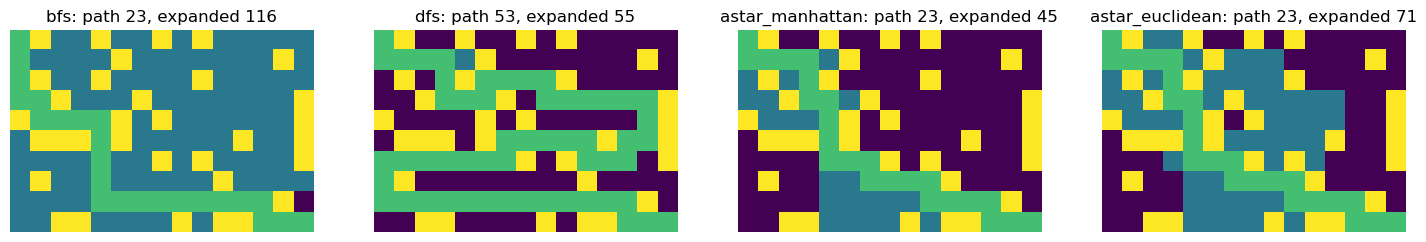

In [30]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3))
for ax, name in zip(axes, ["bfs", "dfs", "astar_manhattan", "astar_euclidean"]):
    path, expanded = results[name]
    picture = grid.astype(float)               # 0 free, 1 wall
    for cell in expanded:
        picture[cell] = 0.4                    # expanded cells
    for cell in path:
        picture[cell] = 0.7                    # final path
    ax.imshow(picture, cmap="viridis")
    ax.set_title(f"{name}: path {len(path) - 1}, expanded {len(expanded)}")
    ax.axis("off")
plt.show()

## Cell 6: 100 random maps

In [32]:
rows = []
for seed in range(100):
    rng = np.random.default_rng(seed)
    g = (rng.random((ROWS, COLS)) < WALL_PROB).astype(int)
    g[START] = 0
    g[GOAL] = 0
    for name in ["bfs", "dfs", "astar_manhattan", "astar_euclidean"]:
        if name == "astar_manhattan":
            path, expanded = astar(grid, START, GOAL, manhattan)
        elif name == "astar_euclidean":
            path, expanded = astar(grid, START, GOAL, euclidean)
        else:
            path, expanded = blind_search(g, START, GOAL, name)
        if path is not None:                      # skip maps with no path
            rows.append({"algo": name, "path": len(path) - 1, "expanded": len(expanded)})

df = pd.DataFrame(rows)
summary = df.groupby("algo")[["path", "expanded"]].mean().round(1)
print(summary)
print("solvable maps:", len(df) // 3)

                 path  expanded
algo                           
astar_euclidean  23.0      71.0
astar_manhattan  23.0      45.0
bfs              23.6     108.9
dfs              32.4      57.3
solvable maps: 114


## Cell 7: Chart of the averages

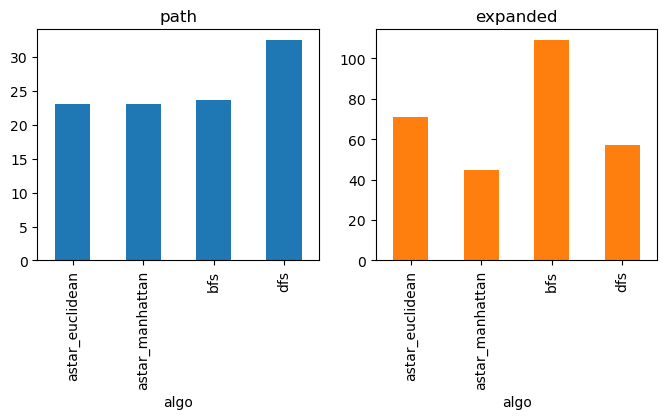

In [33]:
summary.plot(kind="bar", subplots=True, layout=(1, 2), figsize=(8, 3), legend=False)
plt.show()

# Part 2: Motion output
Run Part 1 first. This cell animates the order in which each algorithm opens cells.

## Cell 8: Animation (blue = expanded, orange = final path)

In [35]:
from matplotlib.animation import FuncAnimation
from matplotlib.colors import ListedColormap
from IPython.display import HTML

colors = ListedColormap(["white", "#1f2937", "#93c5fd", "#f59e0b"])   # free, wall, expanded, path
names = ["bfs", "dfs", "astar_manhattan", "astar_euclidean"]
fig, axes = plt.subplots(1, 4, figsize=(15, 3), dpi=60)

def draw(t):
    for ax, name in zip(axes, names):
        path, expanded = results[name]
        picture = grid.copy()                      # 0 free, 1 wall
        for cell in expanded[:t]:
            picture[cell] = 2
        if t >= len(expanded):
            for cell in path:
                picture[cell] = 3
        ax.clear()
        ax.imshow(picture, cmap=colors, vmin=0, vmax=3)
        ax.set_title(f"{name}: {min(t, len(expanded))} expanded", fontsize=9)
        ax.axis("off")

frames = max(len(results[n][1]) for n in names) + 10
anim = FuncAnimation(fig, draw, frames=frames, interval=80)
plt.close(fig)
HTML(anim.to_jshtml())

## Analysis questions
1. Why does A* open fewer cells?
2. Why are BFS and A* paths equally short?
3. Why is the DFS path longer?
4. What happens if WALL_PROB is 0.45?

## Challenges
More walls, different cell costs, diagonal moves, Euclidean heuristic.